# Dyna-Q

Dyna-Q follows each real transition with five planning updates drawn from an empirical model of previously seen state–action pairs.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Action values

A training run starts with empty value estimates. The behaviour policy explores throughout training.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gallery.gridworld import (
    S,
    A,
    GAMMA,
    START,
    choose,
    step,
    q_from_v,
    exact_values,
    policy_report,
)


def train(seed):
    rng = np.random.default_rng(seed)
    q = np.zeros((S, A))
    model = {}
    pairs = []
    trace = []

    def update(s, a, n, r, terminal):
        target = r if terminal else r + GAMMA * q[n].max()
        q[s, a] += 0.12 * (target - q[s, a])

    for episode in range(650):
        epsilon = max(0.07, 0.7 / (1 + episode / 100))
        state = START
        total = 0.0
        for _ in range(60):
            a = choose(q[state], epsilon, rng)
            n, r, done = step(state, a, rng)
            update(state, a, n, r, done)
            pair = (state, a)
            if pair not in model:
                model[pair] = []
                pairs.append(pair)
            model[pair].append((n, r, done))
            for _ in range(5):
                s0, a0 = pairs[rng.integers(len(pairs))]
                seen = model[s0, a0]
                update(s0, a0, *seen[rng.integers(len(seen))])
            total += r
            state = n
            if done:
                break
        trace.append(total)
    return q.argmax(1), trace

## Three training runs

Each final greedy policy plays 240 evaluation episodes on a common independent random stream.

Seed 17: mean return 0.691, goal 100.0%, pit 0.0%, mean steps 8.7, exact discounted start value 0.413
Seed 29: mean return 0.691, goal 100.0%, pit 0.0%, mean steps 8.7, exact discounted start value 0.413
Seed 53: mean return 0.676, goal 98.8%, pit 1.2%, mean steps 8.5, exact discounted start value 0.416
Random policy: mean return -1.715, goal 15.8%, pit 70.0%, mean steps 30.2
Across training seeds: mean return 0.686, sample SD 0.009


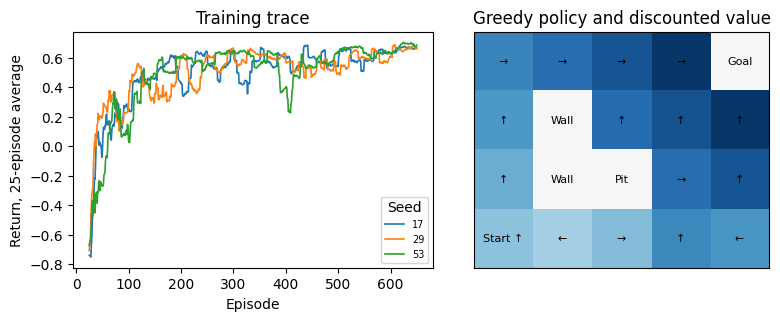

In [3]:
policies, curves = [], []
for seed in (17, 29, 53):
    policy, curve = train(seed)
    policies.append((seed, policy))
    curves.append(curve)
policy_report(policies, curves, "Return, 25-episode average", "Episode")
plt.show()

## Reading the result

The learning trace includes exploratory actions. The final policy is evaluated greedily. Variation across training seeds is reported separately from the random-policy baseline.

## References

[Sutton and Barto, Reinforcement Learning: An Introduction (2018)](https://mitpress.mit.edu/9780262039246/reinforcement-learning/)

[Grid dynamics and policy evaluation](../../../gallery/gridworld.py)